# Approximating Vermeer's Girl with a Pearl Earring using a Genetic Algorithm

In `project_v0`, we built a first working Genetic Algorithm for this problem. This version continues from that baseline, but with a stronger focus on understanding the search process and connecting the implementation to the concepts studied in class.

The main story of this notebook is:

1. Start from a simple baseline GA.
2. Observe how the search evolves over time.
3. Study how selection, crossover, and mutation affect the result.
4. Measure population diversity to detect premature convergence.
5. Try diversity-preserving mechanisms such as fitness sharing or restricted mating.

The goal of the project is to create and run a Genetic Algorithm to approximate Vermeer's "Girl with a Pearl Earring" using only 100 triangles.

Each individual represents one candidate image. Its fitness is measured using the RMSE between the generated image and the target image, comparing the images pixel by pixel. Lower fitness values mean a better approximation.

## Notebook roadmap

The notebook is organized as an experimental story rather than only a sequence of code blocks:

1. Define the representation of a solution and the fitness function.
2. Build a reusable GA loop with configurable operators.
3. Run a baseline experiment and plot the evolution of the search.
4. Compare different crossover and mutation operators.
5. Search for good combinations of operators and parameters.
6. Measure population diversity and use it to explain stagnation or premature convergence.
7. Try mechanisms to preserve diversity, such as fitness sharing or restricted mating.

This structure lets us explain each new implementation choice as a response to something observed in the previous experiment.

## 0. Imports and constants

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from copy import deepcopy
import datetime
from typing import Callable

from src.solution import Solution
from src.selection import tournament_selection
from src.crossover import uniform_crossover
from src.mutation import random_per_gene_mutation

In [5]:
IMAGE_PATH = "girl_pearl_earing.png"
IMAGE_WIDTH = 300
IMAGE_HEIGHT = 400
N_TRIANGLES = 100
TARGET_IMAGE_ALPHA = np.asarray(Image.open(IMAGE_PATH).convert("RGBA"), dtype=np.uint8)
TARGET_IMAGE_NO_ALPHA = np.asarray(Image.open(IMAGE_PATH).convert("RGB"), dtype=np.uint8)

## 1. Defining the solution representation and fitness

For the solution representation we settled on having an array that represents the 100 triangles, each of the triangles being represented also by an array with the following structure: [x1, y1, x2, y2, x3, y3, r, g, b, a]

x1 to y3 represent the coordinates of each of the points of the triangle

r (red), g (green), b (blue) and a (alpha) represent the color channels of the triangle

We can solve this problem with and without transparency, and the solutions will look different, so maybe it is worth trying both of the ways, using an adaptable solution class?

We have defined the `Solution` class in `src/solution.py`, and here is an example of it, using transparency:

In [6]:
example_solution = Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True)

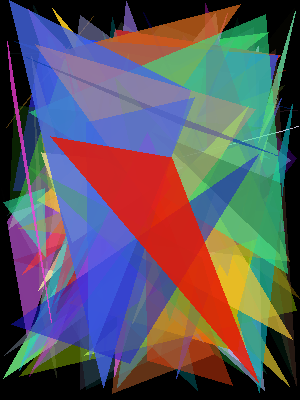

In [7]:
example_solution.render()

In [8]:
example_solution.calculate_fitness()

np.float16(70.2)

And now an example without transparency:

In [9]:
example_solution = Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_NO_ALPHA, use_transparency=False)

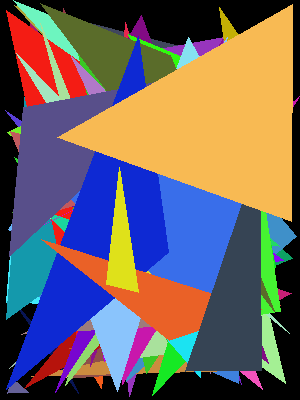

In [10]:
example_solution.render()

In [11]:
example_solution.calculate_fitness()

np.float16(105.56)

## 2. Genetic algorithm definition

here we will create the genetic algorithm loop

check if it makes sense to define this as a class or it should be a function

In [12]:
def genetic_algorithm_loop(
    solution_class: Callable,
    population_size: int,
    n_iterations: int,
    selection_function: Callable,
    crossover_function: Callable,
    crossover_rate: float,
    mutation_function: Callable,
    mutation_rate: float,
    mutation_rate_decay: float | None = None
) -> Solution:
    
    # create population with given size
    population = [ solution_class() for _ in range(population_size) ]
    for individual in population:
        individual.calculate_fitness()
    
    best_solution = population[0]
    best_fitness = population[0].fitness
    
    iteration_start_time = datetime.datetime.now()
    
    for i in range(n_iterations):
        
        # Selection phase
        parents = selection_function(population)
        
        offspring: list[Solution] = []
        # Reproduction with variation phase
        for j in range(0, len(parents), 2):
            parent1 = parents[j]
            parent2 = parents[j + 1] 
            
            child1, child2 = crossover_function(parent1, parent2, crossover_rate)
            
            child1 = mutation_function(child1, mutation_rate)
            child2 = mutation_function(child2, mutation_rate)
            
            offspring.extend([child1, child2])
        
        # Update the population and best solution
        population = offspring
        population_fitness = [ individual.calculate_fitness() for individual in population ]
        average_fitness = np.average(population_fitness)
        best_fitness_index = np.argmin(population_fitness)
        
        if population_fitness[best_fitness_index] <= best_fitness:
            best_fitness = population_fitness[best_fitness_index]
            best_solution = population[best_fitness_index]
        
        iteration_running_time = datetime.datetime.now() - iteration_start_time
        iteration_start_time = datetime.datetime.now()
        
        if ((i + 1) % 10 == 0 or i == 0):
            print(f"Iteration {i + 1} - Fitness: Avg: {average_fitness:.2f}, Best: {best_fitness:.2f}; Mutation rate: {mutation_rate:.3f}; {iteration_running_time.total_seconds():.2f}s/iteration")
        
        if mutation_rate_decay:
            mutation_rate /= 1 + mutation_rate_decay
        
    return best_solution

## 3. Baseline GA run

here we will define a baseline run, using tournament selection because the teacher recommended to try it first, uniform crossover and random per gene mutation as these were the simplest ones

we will always use a random seed to have comparable runs with different hyperparameters and selection, crossover and mutation functions

In [ ]:
# np.random.seed(33)
# best_solution = genetic_algorithm_loop(
#     solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True),
#     population_size = 50,
#     n_iterations = 100,
#     selection_function = lambda p: tournament_selection(p, tournament_size=2),
#     crossover_function = uniform_crossover,
#     crossover_rate = 0.9,
#     mutation_function = random_per_gene_mutation,
#     mutation_rate = 0.01
# )

Iteration 1 - Fitness: Avg: 66.12, Best: 60.84; Mutation rate: 0.010; 1.91s/iteration


KeyboardInterrupt: 

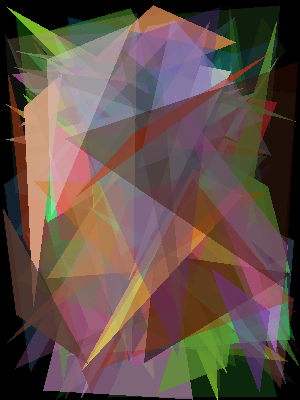

In [ ]:
# best_solution.render()

running without transparency

In [ ]:
# np.random.seed(33)
# best_solution = genetic_algorithm_loop(
#     solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_NO_ALPHA, use_transparency=False),
#     population_size = 50,
#     n_iterations = 100,
#     selection_function = lambda p: tournament_selection(p, tournament_size=2),
#     crossover_function = uniform_crossover,
#     crossover_rate = 0.9,
#     mutation_function = random_per_gene_mutation,
#     mutation_rate = 0.01
# )

Iteration 1 - Fitness: Avg: 92.00, Best: 82.94; Mutation rate: 0.010; 0.82s/iteration
Iteration 10 - Fitness: Avg: 80.94, Best: 76.06; Mutation rate: 0.010; 0.47s/iteration
Iteration 20 - Fitness: Avg: 77.31, Best: 73.56; Mutation rate: 0.010; 0.51s/iteration
Iteration 30 - Fitness: Avg: 74.38, Best: 70.19; Mutation rate: 0.010; 0.68s/iteration
Iteration 40 - Fitness: Avg: 72.12, Best: 68.50; Mutation rate: 0.010; 0.56s/iteration
Iteration 50 - Fitness: Avg: 69.19, Best: 65.06; Mutation rate: 0.010; 0.65s/iteration
Iteration 60 - Fitness: Avg: 67.69, Best: 63.88; Mutation rate: 0.010; 0.77s/iteration
Iteration 70 - Fitness: Avg: 66.38, Best: 63.09; Mutation rate: 0.010; 0.50s/iteration
Iteration 80 - Fitness: Avg: 65.25, Best: 60.03; Mutation rate: 0.010; 0.50s/iteration
Iteration 90 - Fitness: Avg: 64.00, Best: 59.50; Mutation rate: 0.010; 0.53s/iteration
Iteration 100 - Fitness: Avg: 63.22, Best: 59.44; Mutation rate: 0.010; 0.51s/iteration


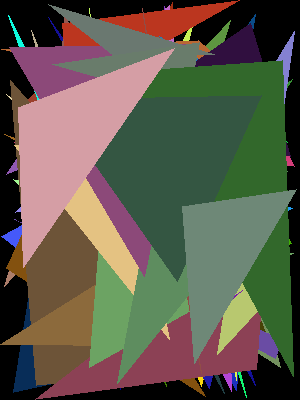

In [ ]:
# best_solution.render()

## 3. Exploring Crossover operators

in this we want to have an overview of the different crossover operators we will try and why they can be good for our problem

## 4. Exploring Mutation operators

in this we want to have an overview of the different mutation operators we will try and why they can be good for our problem

## 5. Hyperparameter tuning

We can do this, just do a random search or grid search, the teacher said it should be coded by us

In [15]:
param_grid = {
    "population_size": 50,
    "n_iterations": 100,
    "tournament_size": [2, 3, 5, 10],
    "crossover_rate": [0.9, 0.8, 0.7],
    "mutation_rate": [0.1, 0.05, 0.01, 0.001],
    "mutation_rate_decay": [None, 1e-3, 1e-4]
}

let's do a random search by hand

In [29]:
random_search_rng = np.random.default_rng()
random_search_results = []

for i in range(20):
    population_size = param_grid["population_size"]
    n_iterations = param_grid["n_iterations"]
    tournament_size = random_search_rng.choice(param_grid["tournament_size"])
    crossover_rate = random_search_rng.choice(param_grid["crossover_rate"])
    mutation_rate = random_search_rng.choice(param_grid["mutation_rate"])
    mutation_rate_decay = random_search_rng.choice(param_grid["mutation_rate_decay"])
    
    print("\n------\n")
    print(f"Random search run {i} with parameters:")
    print(f"population_size: {population_size}")
    print(f"n_iterations: {n_iterations}")
    print(f"tournament_size: {tournament_size}")
    print(f"crossover_rate: {crossover_rate}")
    print(f"mutation_rate: {mutation_rate}")
    print(f"mutation_rate_decay: {mutation_rate_decay}")
    print()
    
    np.random.seed(33)
    best_solution = genetic_algorithm_loop(
        solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True),
        population_size = population_size,
        n_iterations = n_iterations,
        selection_function = lambda p: tournament_selection(p, tournament_size=tournament_size),
        crossover_function = uniform_crossover,
        crossover_rate = crossover_rate,
        mutation_function = random_per_gene_mutation,
        mutation_rate = mutation_rate,
        mutation_rate_decay = mutation_rate_decay
    )
    
    random_search_results.append({
        "best_fitness": best_solution.fitness,
        "best_solution": best_solution,
        "population_size": population_size,
        "n_iterations": n_iterations,
        "tournament_size": tournament_size,
        "crossover_rate": crossover_rate,
        "mutation_rate": mutation_rate,
        "mutation_rate_decay": mutation_rate_decay
    })


------

Random search run 0 with parameters:
population_size: 50
n_iterations: 100
tournament_size: 10
crossover_rate: 0.8
mutation_rate: 0.01
mutation_rate_decay: None

Iteration 1 - Fitness: Avg: 63.66, Best: 59.81; Mutation rate: 0.010; 1.83s/iteration
Iteration 10 - Fitness: Avg: 51.72, Best: 49.81; Mutation rate: 0.010; 1.83s/iteration
Iteration 20 - Fitness: Avg: 46.28, Best: 44.66; Mutation rate: 0.010; 1.74s/iteration
Iteration 30 - Fitness: Avg: 44.78, Best: 43.38; Mutation rate: 0.010; 1.73s/iteration
Iteration 40 - Fitness: Avg: 44.06, Best: 42.22; Mutation rate: 0.010; 0.91s/iteration
Iteration 50 - Fitness: Avg: 42.75, Best: 41.16; Mutation rate: 0.010; 0.81s/iteration
Iteration 60 - Fitness: Avg: 41.44, Best: 39.94; Mutation rate: 0.010; 0.78s/iteration
Iteration 70 - Fitness: Avg: 40.97, Best: 38.81; Mutation rate: 0.010; 0.72s/iteration
Iteration 80 - Fitness: Avg: 40.22, Best: 38.41; Mutation rate: 0.010; 0.71s/iteration
Iteration 90 - Fitness: Avg: 39.09, Best: 37.16

now check what was the best solution and its parameters

maybe try to make the random search parallelizable

In [16]:
def random_search(n_iterations: int, param_grid):
    random_search_rng = np.random.default_rng()
    random_search_results = []

    for i in range(20):
        population_size = param_grid["population_size"]
        n_iterations = param_grid["n_iterations"]
        tournament_size = random_search_rng.choice(param_grid["tournament_size"])
        crossover_rate = random_search_rng.choice(param_grid["crossover_rate"])
        mutation_rate = random_search_rng.choice(param_grid["mutation_rate"])
        mutation_rate_decay = random_search_rng.choice(param_grid["mutation_rate_decay"])
        
        print("\n------\n")
        print(f"Random search run {i} with parameters:")
        print(f"population_size: {population_size}")
        print(f"n_iterations: {n_iterations}")
        print(f"tournament_size: {tournament_size}")
        print(f"crossover_rate: {crossover_rate}")
        print(f"mutation_rate: {mutation_rate}")
        print(f"mutation_rate_decay: {mutation_rate_decay}")
        print()
        
        np.random.seed(33)
        best_solution = genetic_algorithm_loop(
            solution_class = lambda: Solution(IMAGE_WIDTH, IMAGE_HEIGHT, N_TRIANGLES, TARGET_IMAGE_ALPHA, use_transparency=True),
            population_size = population_size,
            n_iterations = n_iterations,
            selection_function = lambda p: tournament_selection(p, tournament_size=tournament_size),
            crossover_function = uniform_crossover,
            crossover_rate = crossover_rate,
            mutation_function = random_per_gene_mutation,
            mutation_rate = mutation_rate,
            mutation_rate_decay = mutation_rate_decay
        )
        
        random_search_results.append({
            "best_fitness": best_solution.fitness,
            "best_solution": best_solution,
            "population_size": population_size,
            "n_iterations": n_iterations,
            "tournament_size": tournament_size,
            "crossover_rate": crossover_rate,
            "mutation_rate": mutation_rate,
            "mutation_rate_decay": mutation_rate_decay
        })

In [19]:
from joblib import Parallel, delayed

def random_search_multithreaded(n_iterations: int, param_grid, n_jobs: int = -1):
    return Parallel(n_jobs=n_jobs)(
        delayed(random_search(n_iterations, param_grid))
    )

In [20]:
random_search_multithreaded(20, param_grid)


------

Random search run 0 with parameters:
population_size: 50
n_iterations: 100
tournament_size: 3
crossover_rate: 0.9
mutation_rate: 0.05
mutation_rate_decay: None

Iteration 1 - Fitness: Avg: 65.38, Best: 59.44; Mutation rate: 0.050; 1.74s/iteration


KeyboardInterrupt: 

## 6. Combat insufficient population diversity

try fitness sharing or restricted mating